In [1]:
import trenchripper as tr

import warnings
warnings.filterwarnings(action="once")

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import pandas as pd
import dask.dataframe as dd

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/'
headpath = HEADPATH

def parse_and_save_futures_results(futures_dict, function_name):
    """
    Parse the results of futures and save them to a DataFrame and a pickle file.
    Args:
        futures_dict (dict): Dictionary with indices as keys and futures as values.
        function_name (str): Name of the function used to generate the futures.
    Returns:
        pd.DataFrame: DataFrame containing the status, done, result, and exception of each future.
    """
    def parse_futures_dict_entry_to_row(future):
        """
        Parse a single future entry to a dictionary row.
        Args:
            future (dask.distributed.Future): Future object to parse.
        Returns:
            dict: Dictionary containing the status, done, result, and exception of the future.
        """
        try:
            result = str(future.result())
        except Exception as e:
            result = str(e)
        future_dict_row = {'status': future.status,
                    'done':future.done(),
                    'result': result,
                    'exception': str(future.exception()),
                    'key': future.key}
        return future_dict_row

    futures_dict_to_table = {index: parse_futures_dict_entry_to_row(future)
                          for index, future in futures_dict.items()}
    
    df_futures = (pd.DataFrame
                  .from_dict(futures_dict_to_table, orient='index')
                  .astype({'status': 'category',
                           'done': bool,
                           'result': 'object',
                           'exception': 'object'})
                  .reset_index()
                  .rename(columns={'index': 'index'})
                  .sort_values(by='index', ascending=True))

    df_futures.to_pickle(f"{headpath}/futures_{function_name}.pkl")

    return df_futures

def deploy_function_in_dask(function, 
                            indices,
                            *args,
                            **kwargs):
    """
    Deploy a function in Dask for each index in the list.
    Args:
        function (callable): Function to deploy.
        indices (list): List of indices to process.
        *args: Additional positional arguments for the function.
        **kwargs: Additional keyword arguments for the function.
    Returns:
        dict: Dictionary with indices as keys and futures as values.
    """
    # futures = []
    futures_dict = {}
    for index in indices:
        future = dask_controller.daskclient.submit(function,
                                               index, # Notice how it is formatted: index is relative to headpath
                                               *args,
                                               **kwargs)
        # futures.append(future)
        futures_dict[index] = future
    # results = dask_controller.daskclient.gather(futures)
    df_futures = parse_and_save_futures_results(futures_dict, function.__name__)
    return df_futures

In [3]:
HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/'
HEADPATH_SEGMENTATION = HEADPATH + '/fluorsegmentation/'
HEADPATH_KYMOGRAPH = HEADPATH + '/kymograph/'
# Open kymograph metadata
kymo_metadata = (
    dd.read_parquet(
    HEADPATH_KYMOGRAPH+'/metadata',
    engine='pyarrow',
    # Load only these columns: ['File Index', 'File Trench Index', 'trenchid']
    columns=['File Index', 'File Trench Index', 'trenchid', 'lane orientation']
    )
    .compute()
    .groupby('trenchid')
    .first()
    .set_index(['File Index', 'File Trench Index'])
)

# List all files
import glob
filenames = glob.glob(HEADPATH_SEGMENTATION + '/segmentation_*.hdf5')
len(filenames)
# Get file indices
file_indices = sorted([int(f.split('_')[-1].split('.')[0]) for f in filenames])

In [13]:
HEADPATH_SEGMENTATION

'/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division//fluorsegmentation/'

In [11]:
def remove_bottom_most_cell_top_oriented_trenches(file_index):

    with h5py.File(HEADPATH_SEGMENTATION + 'segmentation_'+str(file_index)+'.hdf5', 'r+') as f:
        num_trenches = f['data'].shape[0]
        for kymo_index_in_file in range(num_trenches):
            
            segments_all_timepoints = f['data'][kymo_index_in_file][:]
            orientation = kymo_metadata.loc[[(file_index, kymo_index_in_file)], 'lane orientation'].values[0]
            
            if orientation == 'top':
                # I need to remove all bottom segments
                bottom_most_cell_index = np.max(segments_all_timepoints, axis = (1,2))
                # segments_all_timepoints_cleaned = segments_all_timepoints.copy()
                segments_all_timepoints[segments_all_timepoints == bottom_most_cell_index[:, None, None]] = 0
                f['data'][kymo_index_in_file] = segments_all_timepoints
        del segments_all_timepoints
    
    return 0


In [12]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:10:00",
    local=False,
    n_workers=500,
    n_workers_min=20,
    memory="8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

10m
0:10:00


In [14]:
df_futures = deploy_function_in_dask(
    remove_bottom_most_cell_top_oriented_trenches,
    file_indices,
)

In [5]:
HEADPATH_SEGMENTATION

'/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division//fluorsegmentation/'

In [21]:
HEADPATH_BACKUP = HEADPATH + 'fluorseg_backup/fluorsegmentation/'

file_index = 2022
kymo_index_in_file = 136
with h5py.File(HEADPATH_SEGMENTATION + 'segmentation_'+str(file_index)+'.hdf5', 'r') as f:
    segments_all_timepoints_cleaned = f['data'][kymo_index_in_file][:]

with h5py.File(HEADPATH_BACKUP + '/segmentation_'+str(file_index)+'.hdf5', 'r') as f:
    segments_all_timepoints = f['data'][kymo_index_in_file][:]

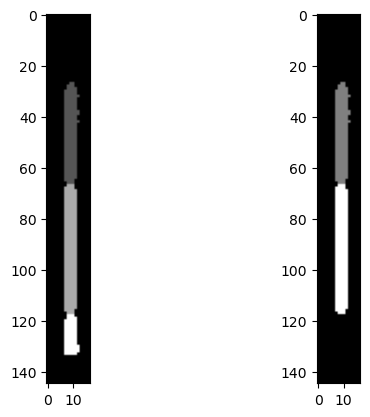

In [28]:
# Make a copy of segments_all_timepoints
fig, axs = plt.subplots(1, 2)  
t = 6
axs[0].imshow(segments_all_timepoints[t], cmap='gray')
# axs[0].set_title('Original Segmentation')
axs[1].imshow(segments_all_timepoints_cleaned[t], cmap='gray')
# axs[1].set_title('Cleaned Segmentation')

In [29]:
dask_controller.shutdown()

Done.


2025-07-08 11:28:15,438 - distributed.deploy.adaptive_core - INFO - Adaptive stop
